# Notebook 02 — T05/T06 và bàn giao T07 của B

Đồ án IE313. Chỉ dùng dữ liệu/source môn đã cung cấp. Notebook đọc CSV gộp sạch của A, không dùng biến RAM từ notebook 01. Giá EUR/kỳ theo README, chưa xác minh metadata gốc. Không gọi giá trị thị trường thật, không ghép cùng listing hoặc suy nhân quả.

Các hàm rõ trong `src/b_tasks.py`; giao thức chung/pipeline trong `src/experiment.py`. Đây là notebook phát triển; khi nộp, A+B tích hợp workflow và đính kèm module cần thiết hoặc gộp vào notebook cuối. AI hỗ trợ code/bản thảo, nhóm kiểm tra và khai báo đúng thực tế.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
assert (ROOT / 'src' / 'experiment.py').exists(), 'Mở notebook từ root hoặc notebooks/'
sys.path.insert(0, str(ROOT))

from src.experiment import load_data, prepare_protocol, load_protocol
from src.b_tasks import build_eda_tables, build_evidence, plot_eda, write_eda_findings


## 1. Kiểm dữ liệu và tạo manifest chung trước phân tích chọn biến

Không dùng giá để chọn split. Seed=0, holdout 20%; 5 folds shuffle seed=0 trong train. Cho phép EDA toàn bộ để mô tả nhưng predictor đã được ấn định theo ý nghĩa, không lọc tự động bằng r/p trên toàn bộ hay train. Config khác đã tồn tại sẽ gây lỗi thay vì tự ghi đè.

In [2]:
df = load_data(ROOT)
config, manifest = prepare_protocol(df, ROOT)
_, train, test, cv = load_protocol(ROOT)
display(pd.DataFrame({'n':[len(df),len(train),len(test)],'scope':['full descriptive','train','held-out test']}))
display(manifest.groupby(['split','cv_fold']).size().rename('n').reset_index())
print('Target:', config['target'], 'transform:', config['target_transform'])
print('Predictors:', config['predictors'])
print('Data SHA256:', config['data_sha256'])


,n,scope
0,51707,full descriptive
1,41365,train
2,10342,held-out test


,split,cv_fold,n
0,test,-1,10342
1,train,0,8273
2,train,1,8273
3,train,2,8273
4,train,3,8273
5,train,4,8273


Target: realSum transform: none
Predictors: {'numeric': ['person_capacity', 'bedrooms', 'dist', 'metro_dist', 'cleanliness_rating', 'guest_satisfaction_overall'], 'categorical': ['city', 'day_type', 'room_type'], 'boolean': ['host_is_superhost']}
Data SHA256: 089643810f3329a971556236f14a7c3c7a347d4c008c488eeac887fe19b24c9c


## 2. Q1/Q2 — bảng giá và cơ cấu theo nhóm

Mỗi cách grouping có tổng n=51.707 riêng, không cộng tổng giữa các grouping. Các tổ hợp thiếu mẫu có n=0, giá NaN. So sánh weekday/weekend là hai nhóm quan sát, không xác minh độc lập hoặc ghép cặp cùng phòng.

In [3]:
summaries, sampling, city_pairs = build_eda_tables(df, ROOT)
display(summaries[summaries['grouping'].eq('city')][['city','n','mean','median','std','iqr']])
display(summaries[summaries['grouping'].eq('room_type')][['room_type','n','mean','median','std','iqr']])
display(city_pairs)
display(sampling[['city','room_type','day_type','n','share_of_city_day','median']])


,city,n,mean,median,std,iqr
0,amsterdam,2080,573.112795,460.244183,430.658406,354.615331
1,athens,5280,151.744121,127.715417,265.880053,72.879807
2,barcelona,2833,293.753706,208.299393,355.467888,168.966882
3,berlin,2484,244.583752,191.175096,235.329289,133.448630
4,budapest,4022,176.513548,152.982093,131.144806,73.083611
5,lisbon,5763,238.210479,225.375235,108.973079,126.172608
6,london,9993,362.469256,261.294950,471.357265,268.585809
7,paris,6688,392.531403,317.597167,330.949745,221.129649
8,rome,9027,205.391950,182.591822,118.618103,102.401047
9,vienna,3537,241.582484,208.494028,397.747165,111.025407


,room_type,n,mean,median,std,iqr
10,Entire home/apt,32648,324.315150,248.456736,351.453080,203.227524
11,Private room,18693,204.940233,166.371516,268.736281,103.178192
12,Shared room,366,143.566164,124.479283,79.210611,59.438206


,city,n_weekdays,n_weekends,mean_weekdays,mean_weekends,median_weekdays,median_weekends,median_difference_weekends_minus_weekdays
0,amsterdam,1103.0,977.0,545.020526,604.828018,430.248635,491.645771,61.397136
1,athens,2653.0,2627.0,155.866982,147.580456,127.715417,127.715417,0.000000
2,barcelona,1555.0,1278.0,288.391667,300.277940,208.532129,204.691973,-3.840156
3,berlin,1284.0,1200.0,240.220422,249.252516,187.786295,192.460503,4.674208
4,budapest,2074.0,1948.0,168.429367,185.120628,147.459698,160.031959,12.572261
5,lisbon,2857.0,2906.0,236.345459,240.044051,223.030019,227.720450,4.690432
6,london,4614.0,5379.0,360.230348,364.389747,256.355982,268.115431,11.759449
7,paris,3130.0,3558.0,398.786678,387.028589,318.529220,316.199087,-2.330133
8,rome,4492.0,4535.0,201.618053,209.130063,179.786314,184.462161,4.675847
9,vienna,1738.0,1799.0,240.384834,242.739524,204.520487,212.000093,7.479606


,city,room_type,day_type,n,share_of_city_day,median
0,amsterdam,Entire home/apt,weekdays,538,0.487761,625.336864
1,amsterdam,Entire home/apt,weekends,588,0.601842,614.440044
2,amsterdam,Private room,weekdays,559,0.506800,319.640053
3,amsterdam,Private room,weekends,385,0.394063,350.338622
4,amsterdam,Shared room,weekdays,6,0.005440,258.008577
5,amsterdam,Shared room,weekends,4,0.004094,229.770581
6,athens,Entire home/apt,weekdays,2447,0.922352,133.339582
7,athens,Entire home/apt,weekends,2425,0.923106,133.339582
8,athens,Private room,weekdays,201,0.075763,82.253416
9,athens,Private room,weekends,196,0.074610,78.152462


## 3. Q3/Q4 — Pearson và ANOVA có giới hạn

Pearson tính trên giá gốc: r/p/n gộp và theo city, chia `full_descriptive` và `train_descriptive`. Chỉ số |r| khoảng 0,3 là tham khảo bài giá xe, không bác bỏ mọi quan hệ trong Airbnb.

ANOVA một yếu tố theo city/room_type và room_type trong city. Xuất F/p, n từng nhóm, ratio phương sai để đọc giới hạn. Lệch phải, nhóm không cân bằng và tọa độ lặp khiến giả định chưa bảo đảm; p nhỏ không chứng minh nhân quả/độ lớn hoặc mọi cặp khác nhau. P underflow để NaN kèm cờ rõ, không trình bày xác suất đúng bằng 0.

In [4]:
pearson, anova, corr = build_evidence(df, train, config, ROOT)
display(pearson[(pearson['scope']=='full_descriptive') & (pearson['context']=='all_cities')][['feature','n','r','p_display','used_in_core_model']])
display(pearson[(pearson['scope']=='full_descriptive') & (pearson['feature']=='person_capacity')][['context','n','r','p_display']])
display(anova[['scope','context','feature','n','n_groups','min_group_n','f','p_display','variance_ratio_max_min']])


,feature,n,r,p_display,used_in_core_model
0,person_capacity,51707,0.203077,underflow_float64; not exact zero,True
1,bedrooms,51707,0.221653,underflow_float64; not exact zero,True
2,dist,51707,-0.044725,2.5631e-24,True
3,metro_dist,51707,-0.061025,7.3765e-44,True
4,cleanliness_rating,51707,-0.006082,1.6668e-01,True
5,guest_satisfaction_overall,51707,-0.001888,6.6778e-01,True
6,attr_index,51707,0.178228,underflow_float64; not exact zero,False
7,attr_index_norm,51707,0.292396,underflow_float64; not exact zero,False
8,rest_index,51707,0.134722,5.7638e-208,False
9,rest_index_norm,51707,0.144094,6.5072e-238,False


,context,n,r,p_display
0,all_cities,51707,0.203077,underflow_float64; not exact zero
12,amsterdam,2080,0.527603,2.0514e-149
24,athens,5280,0.091463,2.7682e-11
36,barcelona,2833,0.374672,4.0989e-95
48,berlin,2484,0.312270,2.5747e-57
60,budapest,4022,0.235011,1.3556e-51
72,lisbon,5763,0.572876,underflow_float64; not exact zero
84,london,9993,0.352445,3.9353e-290
96,paris,6688,0.395620,1.8522e-249
108,rome,9027,0.403907,underflow_float64; not exact zero


,scope,context,feature,n,n_groups,min_group_n,f,p_display,variance_ratio_max_min
0,full_descriptive,all_cities,city,51707,10,2080,605.718645,underflow_float64; not exact zero,18.709491
1,full_descriptive,all_cities,room_type,51707,3,366,846.137548,underflow_float64; not exact zero,19.686476
2,full_descriptive,amsterdam,room_type,2080,3,10,207.469249,7.1416e-83,20.870745
3,full_descriptive,athens,room_type,5280,3,11,5.057589,6.3917e-03,813.499736
4,full_descriptive,barcelona,room_type,2833,3,12,380.346414,5.0185e-147,529.648501
5,full_descriptive,berlin,room_type,2484,3,73,202.485855,3.4849e-82,32.870138
6,full_descriptive,budapest,room_type,4022,3,14,65.088367,1.5157e-28,4.963153
7,full_descriptive,lisbon,room_type,5763,3,74,1496.943603,underflow_float64; not exact zero,11.760637
8,full_descriptive,london,room_type,9993,3,50,661.010620,2.4903e-270,29.135059
9,full_descriptive,paris,room_type,6688,3,94,113.704990,2.7536e-49,15.869149


## 4. Hình trả lời câu hỏi

7 hình gồm số mẫu city, giá theo loại phòng, chênh nhóm ngày/city, pivot trung vị+n, Pearson core, scatter sức chứa theo city, cơ cấu loại phòng của các nhóm ngày. Trục log chỉ là cách hiển thị, không đổi target mô hình hoặc loại outlier. Scatter tính r trên giá gốc dù hiển thị trục log.

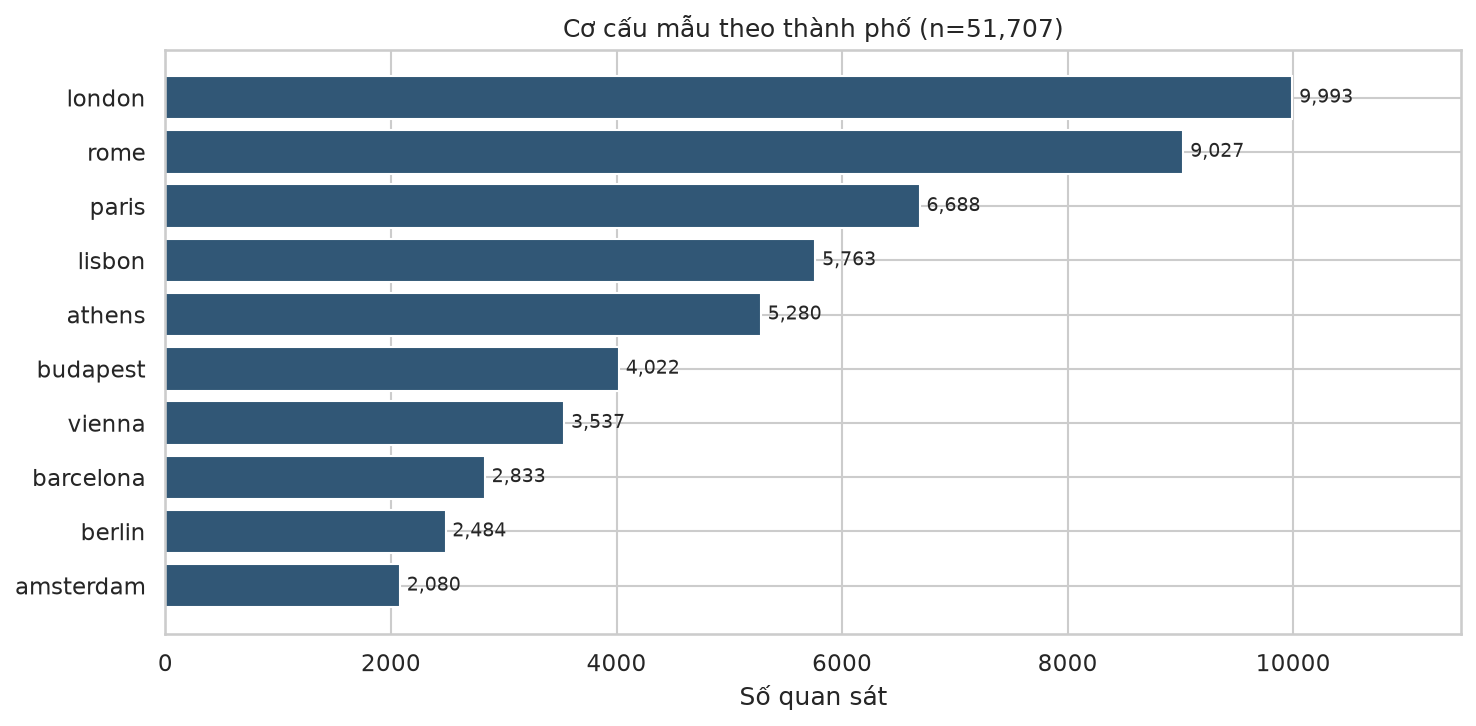

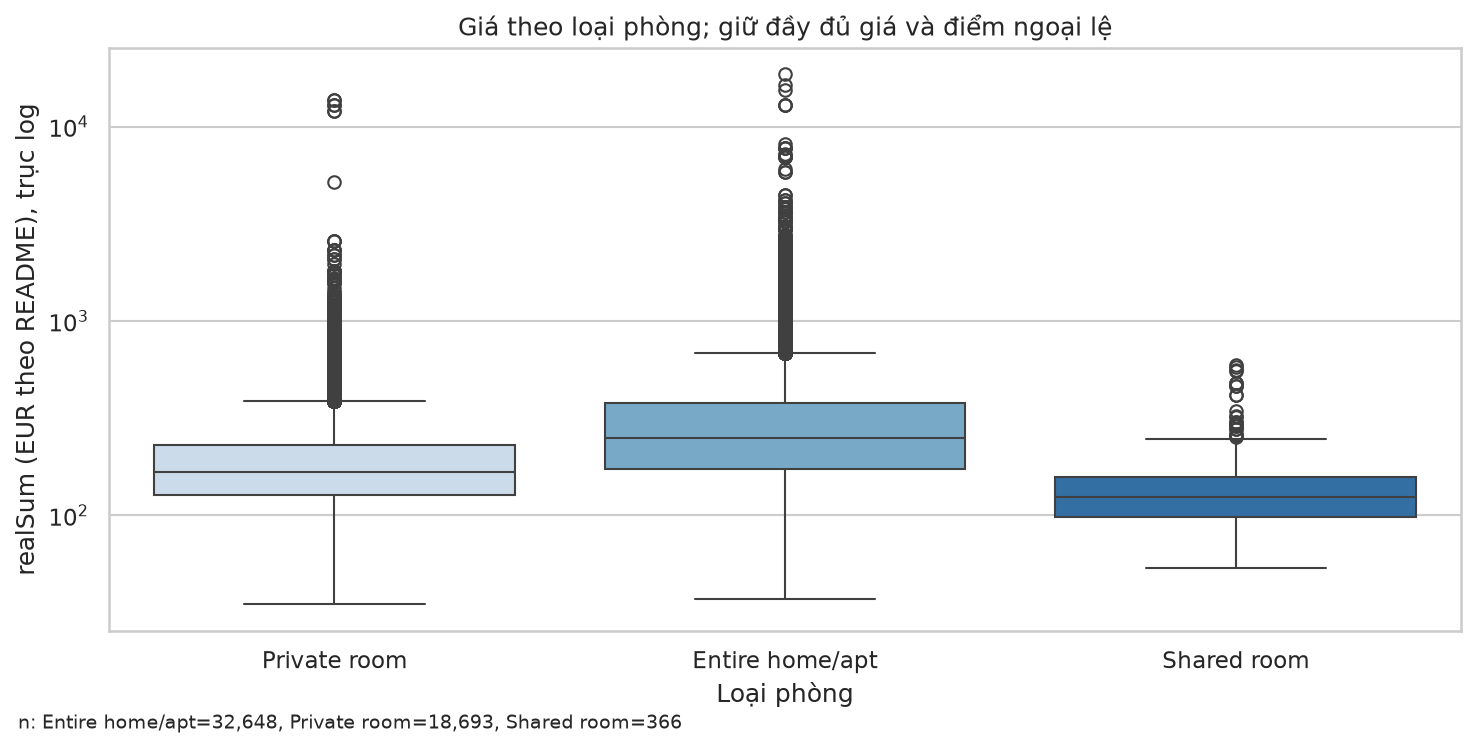

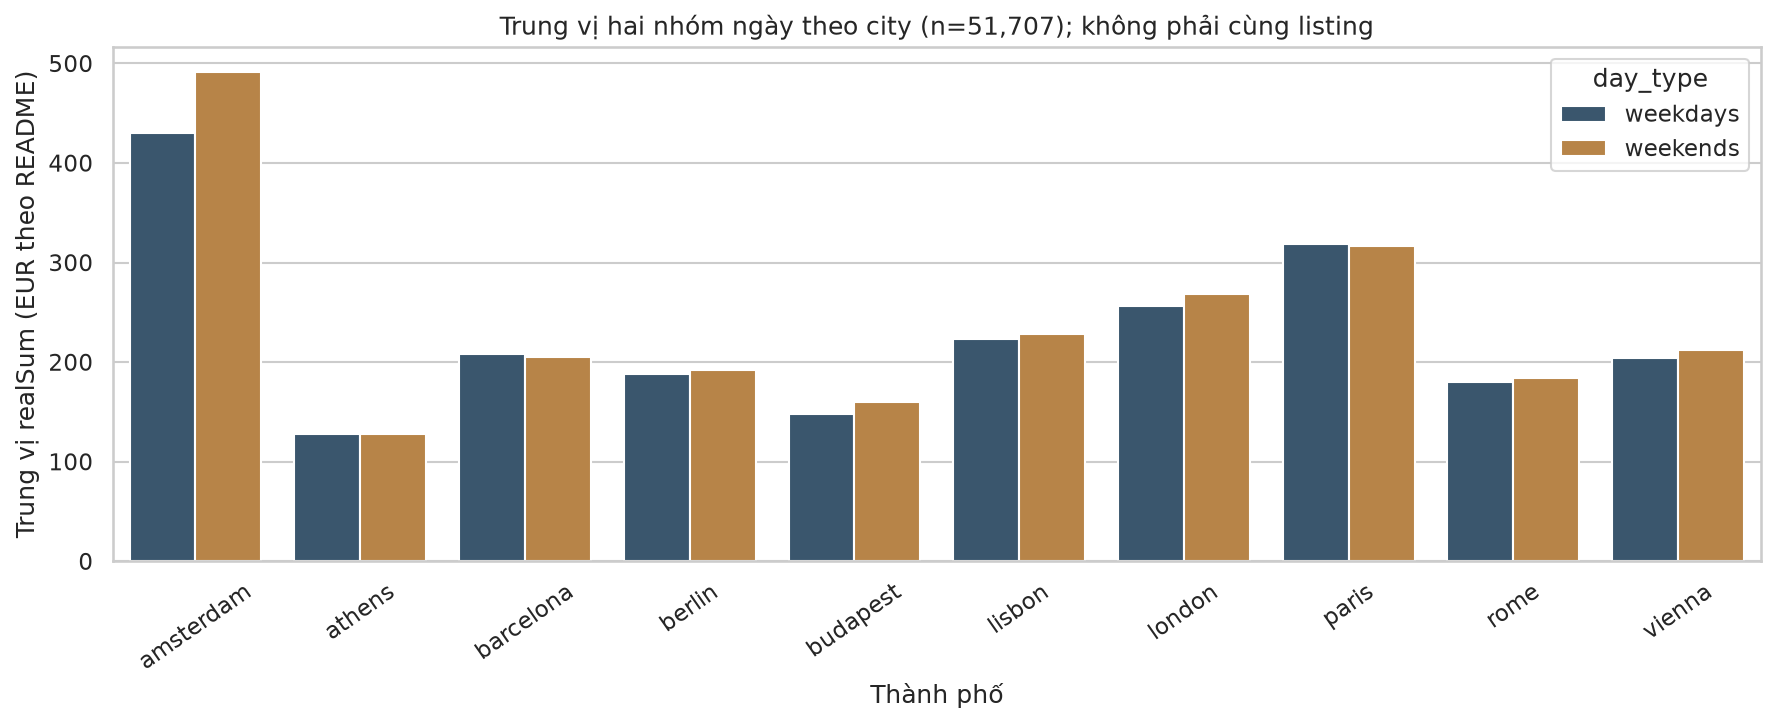

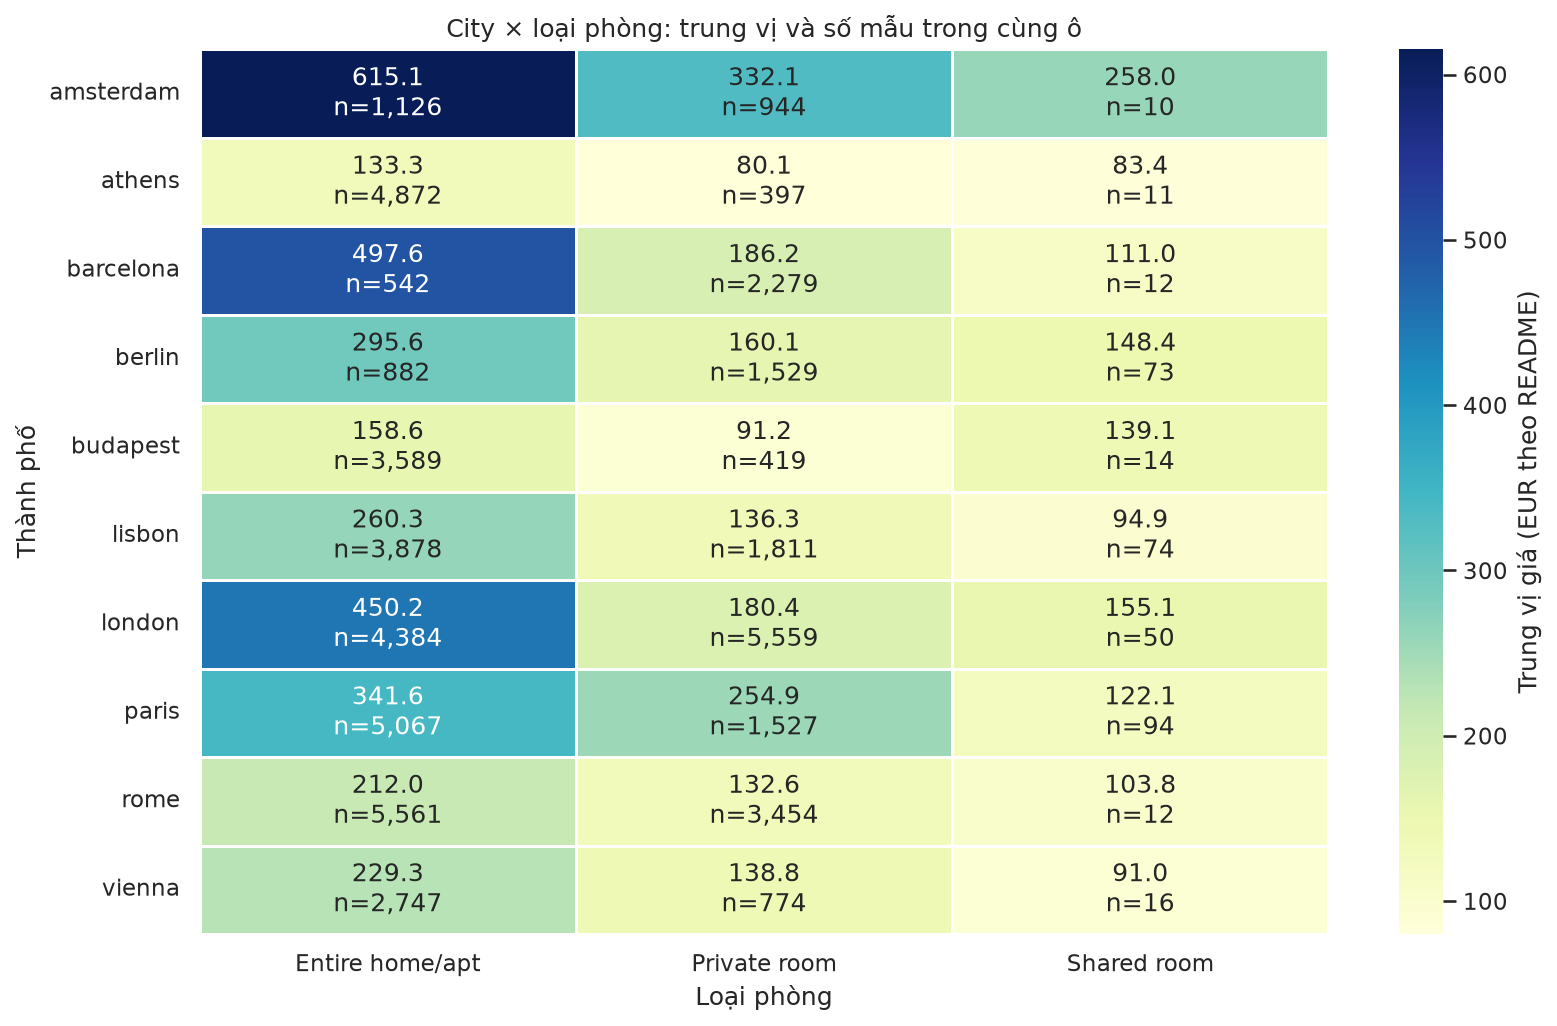

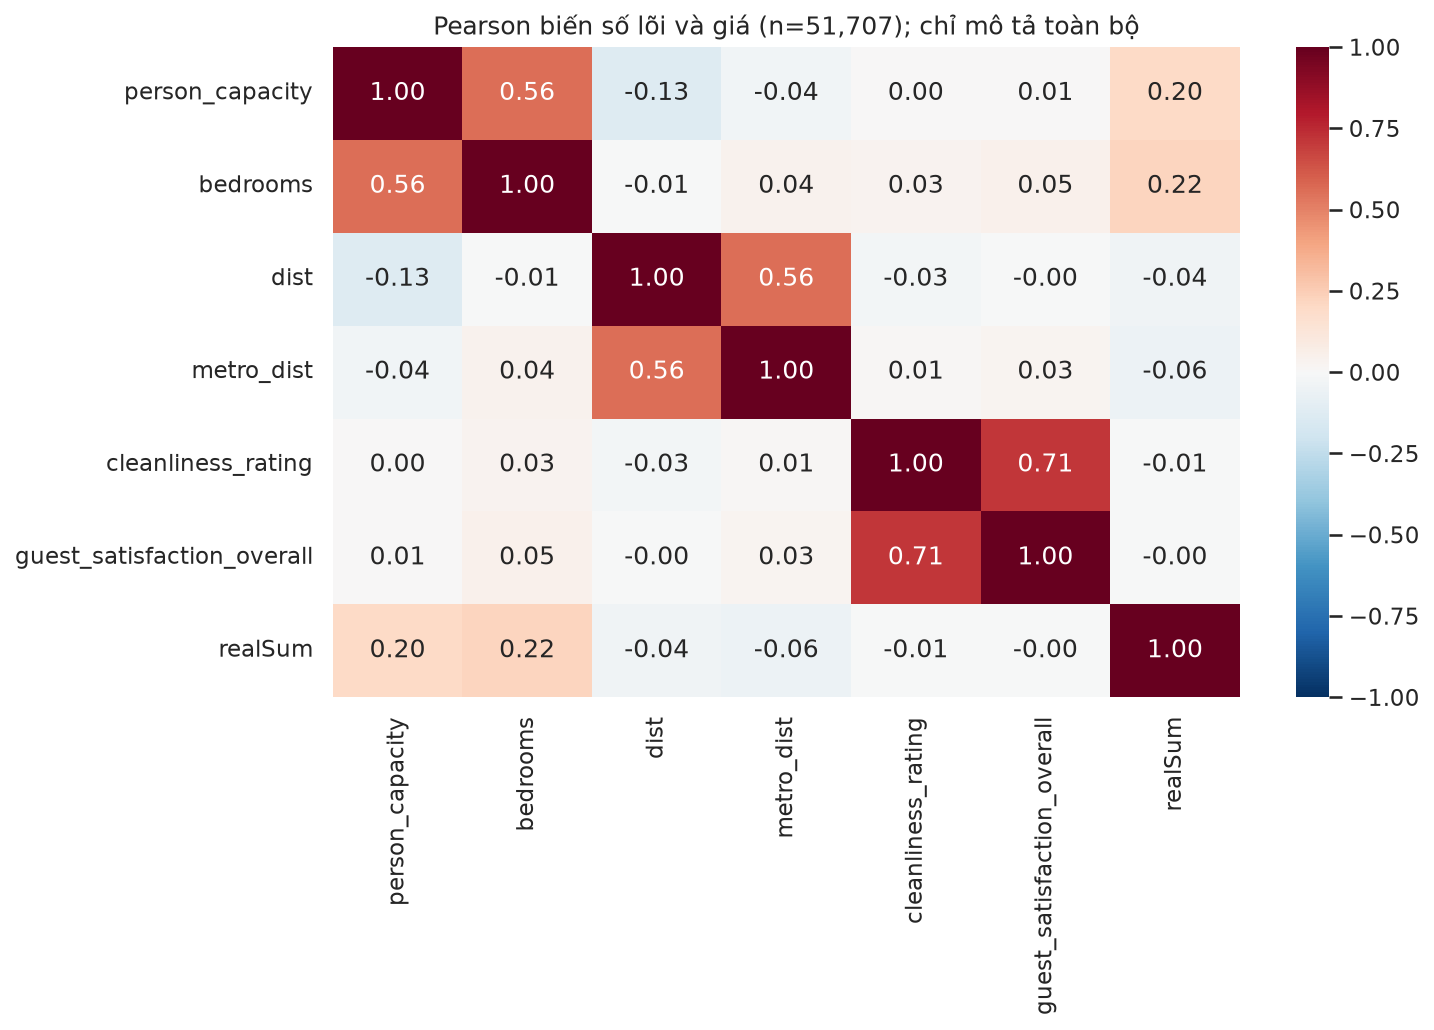

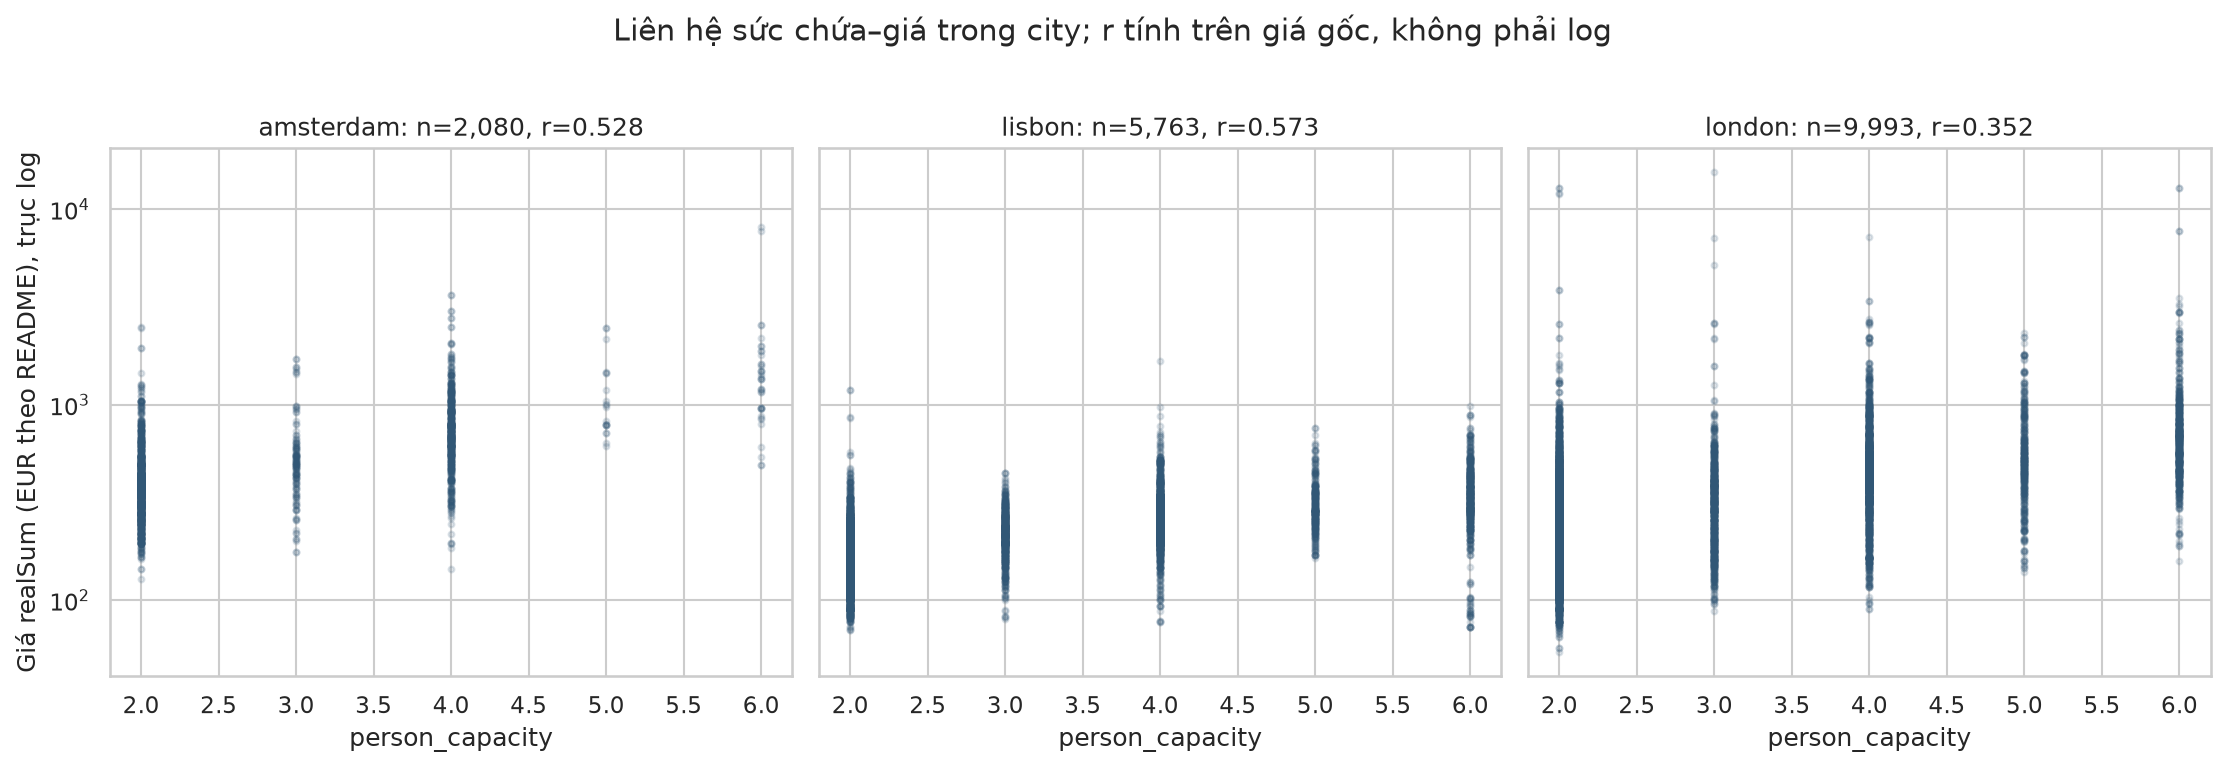

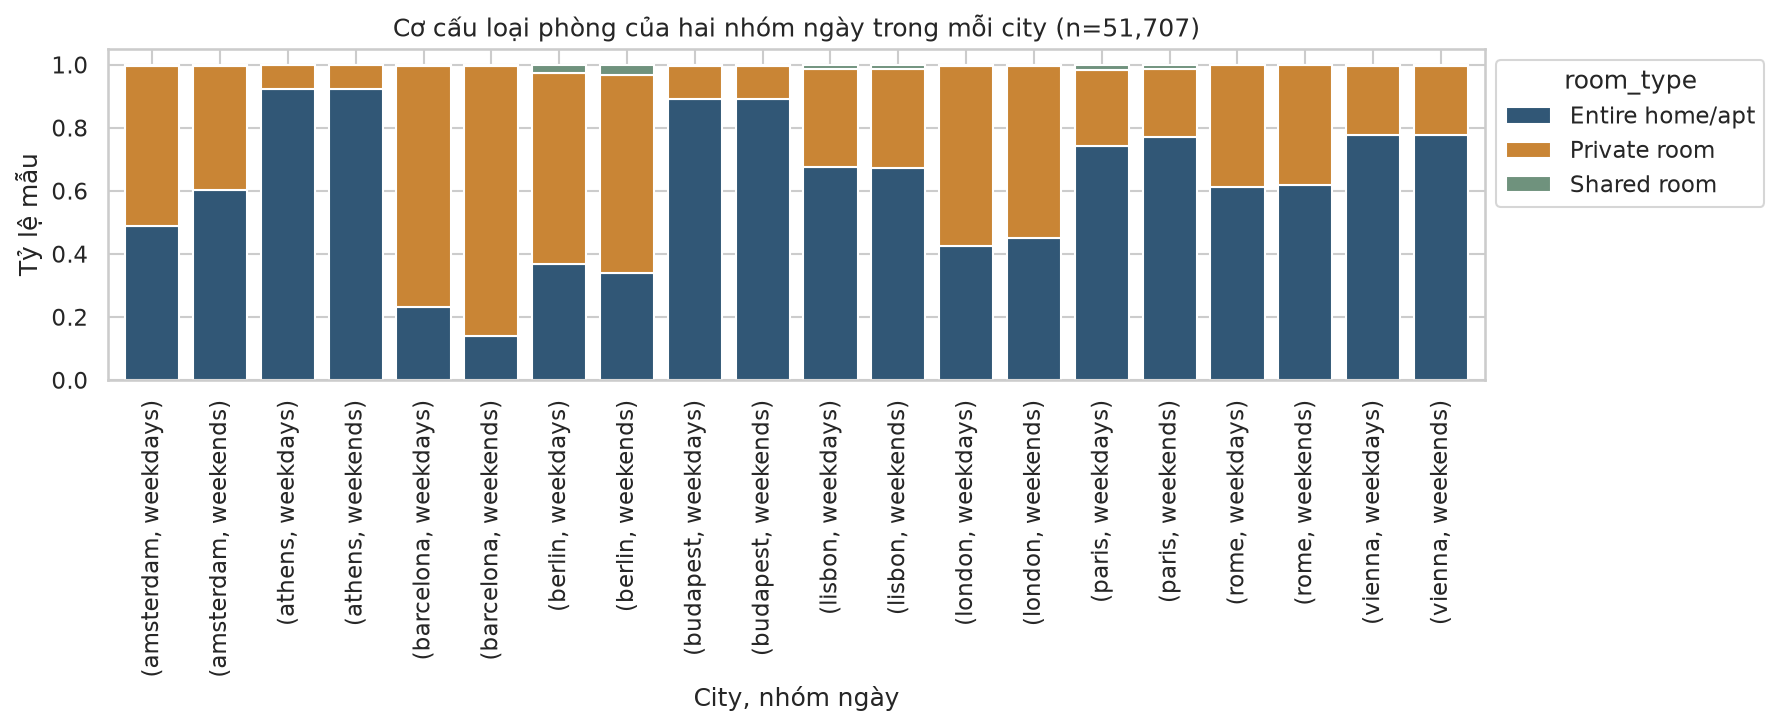

In [5]:
plot_eda(df, summaries, sampling, pearson, corr, ROOT)
for filename in ['b_01_counts_by_city.png','b_02_price_by_room_type.png','b_03_city_day_median.png',
                 'b_04_city_room_median_count.png','b_05_core_correlation.png',
                 'b_06_capacity_price_within_city.png','b_07_room_composition_by_day.png']:
    display(Image(filename=str(ROOT/'outputs/figures'/filename), width=1000))


## 5. Nhận xét thực tế và bàn giao

Bản nhận xét dưới đây được sinh từ số liệu vừa tính, không placeholder. Chưa có test metrics hoặc mô hình thắng chung. A cần kiểm protocol và dùng cùng manifest cho T08, không sửa split hoặc bỏ outlier để làm đẹp điểm.

In [6]:
write_eda_findings(df, summaries, city_pairs, pearson, anova, ROOT)
display(Markdown((ROOT/'reports/eda_findings.md').read_text(encoding='utf-8')))
assert len(train)==41365 and len(test)==10342
assert manifest[['source_file','source_row']].duplicated().sum()==0
assert sum(len(valid) for _,valid in cv)==len(train)
assert config['target'] not in sum(config['predictors'].values(), [])
assert (sampling['n']==0).sum()==sampling['median'].isna().sum()
print('T05/T06 và artifact T07 đã tạo; A kiểm tra trước dùng T08.')


# Phát hiện T05–T06 của B

Ngày chạy: 12/10/2026. Các bảng `full_descriptive` mô tả toàn bộ 51.707 quan sát; bảng `train_descriptive` chỉ train. Đây không phải kết quả test mô hình, không dùng bảng mô tả để tự động lọc predictor.

## Q1: giá và cơ cấu mẫu

- Mean giá 279.88, median 211.34, std 327.95, skew 21.42; đơn vị EUR/kỳ giá theo README, chưa xác minh metadata gốc. Mean cao hơn median; không dùng mean một mình để nói giá điển hình.
- Median Amsterdam 460.24, Athens 127.72. Khác mặt bằng giá theo nhóm quan sát; không kết luận city gây chênh giá hoặc dữ liệu đại diện toàn thị trường.
- Entire home/apt: n=32,648, median 248.46; Private room: n=18,693, median 166.37; Shared room: n=366, median 124.48. Shared chỉ 0.708%: đọc n từng ô trước so sánh.
- Cờ IQR và lý do giữ giá gốc dùng phần A đã review; chưa chứng minh giá cao là luxury/biệt thự. Hình B giữ đủ giá, dùng trục log có chú thích.

## Q2: hai nhóm ngày

- Chênh median gộp theo city lớn nhất về trị tuyệt đối tại amsterdam: weekdays 430.25 (n=1,103), weekends 491.65 (n=977), chênh 61.40.
- Đây là so sánh hai tập quan sát, không ghép cặp cùng phòng. Đối chiếu `eda_day_comparison_by_room.csv` và biểu đồ cơ cấu loại phòng để tách sự khác cơ cấu; không nói “cùng phòng tăng giá cuối tuần”.
- Bảng nhóm tạo đủ tổ hợp: count=0 cho tổ hợp không có mẫu, giá giữ NaN; không điền giá 0. `eda_sampling_counts.csv` lưu tỷ lệ theo city/day và n.

## Q3: Pearson

- r sức chứa–giá toàn bộ 0.203, n=51,707; r tuyến tính gộp nhỏ không phủ nhận liên hệ trong city. Xem bảng r/p/n từng city và scatter; dữ liệu tọa độ lặp làm độc lập mẫu chưa xác minh.
- Kế hoạch môn dùng ngưỡng khoảng 0,3 để tham khảo bài giá xe; không dùng ngưỡng này loại toàn bộ yếu tố Airbnb. Allowlist mô hình cố định theo ý nghĩa; các biến index/tọa độ vẫn được mô tả nhưng chưa đưa vào core do metadata/diễn giải.

## Q4: ANOVA

- ANOVA giá theo room_type toàn bộ: F=846.138, p=underflow_float64; not exact zero, min nhóm n=366; tỷ số phương sai nhóm lớn nhất/nhỏ nhất 19.69. Báo F/p đi cùng mean/median/n, không gọi p nhỏ là tác động lớn hay mọi cặp khác nhau.
- Giả định độc lập, phương sai và dạng phần dư không được đảm bảo: giá lệch phải, nhóm mất cân đối, tọa độ lặp. Đây là áp dụng kỹ thuật môn với giới hạn, không kết luận nhân quả/định giá đúng.
- p dưới độ biểu diễn float64: bảng để giá trị numeric trống với `p_underflow=True`, nhãn underflow; không khẳng định xác suất đúng bằng 0. Giữ thống kê F/r và n để đọc kết quả.

## Đầu ra và sử dụng

`eda_group_summary.csv`, `eda_sampling_counts.csv`, hai bảng chênh ngày, `pearson_price_evidence.csv`, `anova_price_evidence.csv`, `anova_group_details.csv`, `feature_evidence.csv`; 7 hình có tiền tố `b_`. Một dòng mỗi phép xét có scope/context để tránh nhầm EDA toàn bộ với kết quả trên train.

Các hình/bảng được tạo bằng Python. AI hỗ trợ code và bản thảo trong lượt này; nhóm cần kiểm tra, hiểu và khai báo công cụ thực tế khi viết đoạn minh bạch. Phần nhận xét này chỉ dùng số tính từ data, không sao chép kết quả mô hình ngoài.


T05/T06 và artifact T07 đã tạo; A kiểm tra trước dùng T08.
